In [1]:
import numpy as np 
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt


In [2]:
df=pd.read_csv("MagicBricks.csv")

In [3]:
df.head()

,Area,BHK,Bathroom,Furnishing,Locality,Parking,Price,Status,Transaction,Type,Per_Sqft
0,800.0,3,2.0,Semi-Furnished,Rohini Sector 25,1.0,6500000,Ready_to_move,New_Property,Builder_Floor,NaN
1,750.0,2,2.0,Semi-Furnished,"J R Designers Floors, Rohini Sector 24",1.0,5000000,Ready_to_move,New_Property,Apartment,6667.0
2,950.0,2,2.0,Furnished,"Citizen Apartment, Rohini Sector 13",1.0,15500000,Ready_to_move,Resale,Apartment,6667.0
3,600.0,2,2.0,Semi-Furnished,Rohini Sector 24,1.0,4200000,Ready_to_move,Resale,Builder_Floor,6667.0
4,650.0,2,2.0,Semi-Furnished,Rohini Sector 24 carpet area 650 sqft status R...,1.0,6200000,Ready_to_move,New_Property,Builder_Floor,6667.0


In [4]:
df.shape

(1259, 11)

# 🛑 Why You Must Drop `Per_Sqft` Before Training

When building a real estate prediction model, including **Price per Square Foot (`Per_Sqft`)** in your features (`X`) causes two critical issues: **Data Leakage** and **Multicollinearity**.

---

## 1. Data Leakage (The Biggest Issue)
`Per_Sqft` is calculated directly using your target variable (`Price`):

$$\text{Per\_Sqft} = \frac{\text{Price}}{\text{Area}}$$

* **The Problem:** By keeping `Per_Sqft`, you are feeding the "answer" into your model during training. 
* **The Consequence:** Your model will look amazing during cross-validation, but it will fail completely in the real world when predicting prices for new houses where the price (and therefore `Per_Sqft`) is unknown.

---

## 2. Multicollinearity
Because `Per_Sqft` is mathematically derived from `Area` and `Price`, it introduces strong linear dependencies among your features.
* **The Consequence:** For linear models, this makes feature coefficients unstable and unreliable.

---





In [5]:
df.drop(columns=['Per_Sqft'], errors='ignore', inplace=True)
df.drop(columns=['Locality'], errors='ignore', inplace=True)


In [6]:
df.head()

,Area,BHK,Bathroom,Furnishing,Parking,Price,Status,Transaction,Type
0,800.0,3,2.0,Semi-Furnished,1.0,6500000,Ready_to_move,New_Property,Builder_Floor
1,750.0,2,2.0,Semi-Furnished,1.0,5000000,Ready_to_move,New_Property,Apartment
2,950.0,2,2.0,Furnished,1.0,15500000,Ready_to_move,Resale,Apartment
3,600.0,2,2.0,Semi-Furnished,1.0,4200000,Ready_to_move,Resale,Builder_Floor
4,650.0,2,2.0,Semi-Furnished,1.0,6200000,Ready_to_move,New_Property,Builder_Floor


In [7]:
df.columns

Index(['Area', 'BHK', 'Bathroom', 'Furnishing', 'Parking', 'Price', 'Status',
       'Transaction', 'Type'],
      dtype='object')

In [8]:
X=df[['Area','BHK', 'Bathroom', 'Furnishing', 'Parking', 
       'Status', 'Transaction', 'Type']]
y=df['Price']

In [9]:
from sklearn.model_selection import train_test_split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [11]:
X_train.head()

,Area,BHK,Bathroom,Furnishing,Parking,Status,Transaction,Type
243,4300.0,4,4.0,Unfurnished,2.0,Ready_to_move,Resale,Builder_Floor
514,504.0,3,1.0,Semi-Furnished,NaN,Ready_to_move,Resale,Apartment
966,1000.0,3,2.0,Furnished,2.0,Ready_to_move,Resale,Apartment
199,1295.0,3,2.0,Semi-Furnished,1.0,Ready_to_move,New_Property,Apartment
270,2650.0,4,4.0,Unfurnished,2.0,Ready_to_move,New_Property,Builder_Floor


In [12]:
print(y_train.isnull().sum())
print(X_train.isnull().sum())

0
Area            0
BHK             0
Bathroom        2
Furnishing      5
Parking        30
Status          0
Transaction     0
Type            5
dtype: int64


In [13]:
print(y_train.duplicated().sum())
print(X_train.duplicated().sum())

756
215


In [14]:
# 1. Combine X_train and y_train temporarily
train_df = X_train.copy()
train_df['Price'] = y_train

# 2. Drop duplicate rows
train_df = train_df.drop_duplicates()

# 3. Separate them back into X_train and y_train
X_train = train_df.drop(columns=['Price'])
y_train = train_df['Price']

print("New X_train shape after dropping duplicates:", X_train.shape)

New X_train shape after dropping duplicates: (932, 8)


In [15]:
X_train.columns

Index(['Area', 'BHK', 'Bathroom', 'Furnishing', 'Parking', 'Status',
       'Transaction', 'Type'],
      dtype='object')

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import SelectKBest, mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
num_cols=['Area', 'Bathroom', 'Parking']
cat_cols=['Furnishing','Status', 'Transaction', 'Type','BHK']


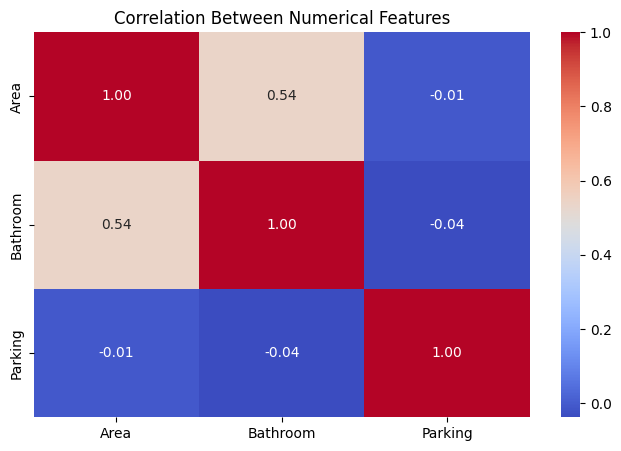

In [17]:
train_corr = X_train[num_cols].corr()

plt.figure(figsize=(8, 5))
sns.heatmap(train_corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Between Numerical Features')
plt.show()


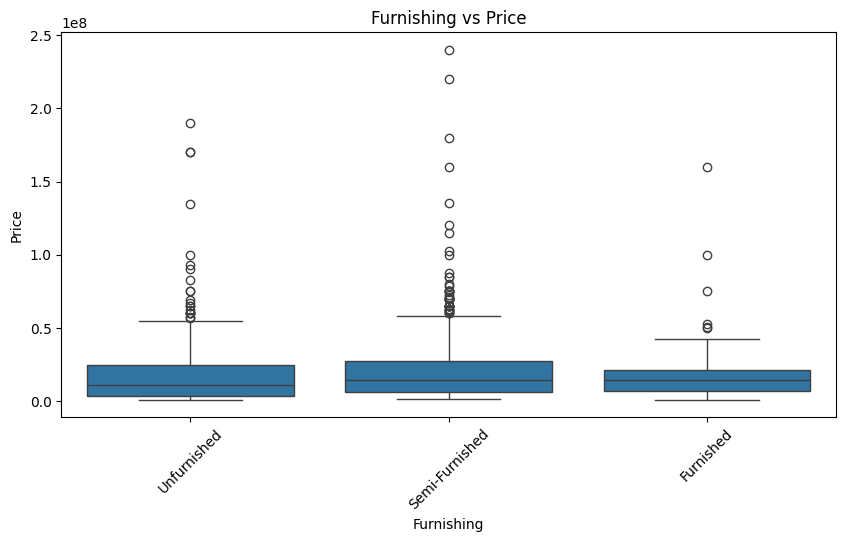

In [18]:

plt.figure(figsize=(10, 5))

sns.boxplot(x=X_train['Furnishing'], y=y_train)

plt.title('Furnishing vs Price')
plt.xlabel('Furnishing')
plt.ylabel('Price')
plt.xticks(rotation=45)

plt.show()



In [19]:
train_data = X_train[num_cols].copy()
train_data['Price'] = y_train

print(train_data.corr()['Price'].sort_values(ascending=False))

Price       1.000000
Bathroom    0.736096
Area        0.585746
Parking     0.004097
Name: Price, dtype: float64


In [20]:

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical pipeline
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        drop='if_binary'
    ))
])

# Preprocessing
preprocess = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

# Leakage-safe feature selection and model pipeline
model = Pipeline([
    ('preprocess', preprocess),
    ('selector', SelectKBest(
        score_func=mutual_info_regression,
        k=10
    )),
    ('clf', LinearRegression())
])

# Train model
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))



MAE: 10249760.21337617
R2 Score: 0.5799999204199775


In [21]:
rf_model = Pipeline([
    ('preprocess', preprocess),
    ('clf', RandomForestRegressor(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest MAE:", mean_absolute_error(y_test, y_pred_rf))
print("Random Forest R2:", r2_score(y_test, y_pred_rf))

Random Forest MAE: 6967777.88848332
Random Forest R2: 0.7683348557169923
